# Task 1 – Netflix Content Recommendation System

**Goal:** build a recommender that, given a Netflix title, suggests similar titles based on genres, categories and other content attributes.

**My approach in one paragraph:** I turn every title into a small "bag of tokens" (its genres, director, country, rating, type and the meaningful words in its title). Then I use TF-IDF to give rare, informative tokens more weight than common ones, and cosine similarity to find the titles whose token profile looks most like the one I picked. This is called *content-based filtering*, because it only looks at what a title *is*, not at who watched it.

**A note on this dataset:** it has no `description` or `cast` column, so the recommender works from genres, director, country, rating, type and title words. That is a bit less rich than text descriptions, so I'll be honest about the limits in the evaluation.

# New Section

In [ ]:
import re
import warnings
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import linear_kernel

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Step 0 – Load and clean the data

Before any modelling I load the file and tidy it. What I do, and why:

- **Remove exact duplicate rows** (there are none in this file, but it is a good habit).
- **Parse `date_added`.** In this dataset dates look like `9/25/2021`, so I tell pandas the exact format.
- **Missing values** are not blank here. The file writes `Not Given` for unknown directors and countries, and I keep that in mind (for example `has_director` is 0 when the director is `Not Given`).
- **Turn `duration` into a number.** `"90 min"` becomes 90 and `"2 Seasons"` becomes 2.
- **Simplify genre names.** Netflix names the same genre differently for movies and shows (`Dramas` vs `TV Dramas`, `International Movies` vs `International TV Shows`). I merge them so a genre means the same thing for both types.

In [ ]:
DATA_PATH = "Dataset.csv"      # change this if the file is in another folder

df = pd.read_csv(DATA_PATH).drop_duplicates().reset_index(drop=True)
print("Dataset shape:", df.shape)

# Dates (format in this file is month/day/year)
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%m/%d/%Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# Duration as a number: "90 min" -> 90, "2 Seasons" -> 2
df["duration_num"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")

# Helpers for comma separated columns
def split_items(text):
    return [p.strip() for p in str(text).split(",") if p.strip()]

def simplify_genre(name):
    """'TV Dramas' and 'Dramas' -> 'Dramas';  'International Movies' -> 'International'."""
    name = name.strip()
    if name in ("Movies", "TV Shows"):
        return "Other"
    name = re.sub(r"^TV\s+", "", name)
    name = re.sub(r"\s+(Movies|TV Shows|TV)$", "", name)
    return name

# Handy columns used by several tasks
df["genre_list"] = df["listed_in"].apply(lambda s: [simplify_genre(g) for g in split_items(s)])
df["n_genres"] = df["genre_list"].apply(len)
df["country_main"] = df["country"].apply(lambda s: split_items(s)[0] if split_items(s) else "Not Given")
df["has_director"] = (df["director"].str.strip() != "Not Given").astype(int)
df["years_to_add"] = (df["year_added"] - df["release_year"]).clip(lower=0)

# 0/1 columns for the 30 most common (simplified) genres, most common first
top_genres = pd.Series([g for lst in df["genre_list"] for g in lst]).value_counts().head(30).index.tolist()
genre_cols = []
for g in top_genres:
    col = "genre_" + g
    df[col] = df["genre_list"].apply(lambda lst, g=g: int(g in lst))
    genre_cols.append(col)

print(df["type"].value_counts().to_dict(), "| date range:", df["date_added"].min().date(), "to", df["date_added"].max().date())
df.head(3)

Dataset shape: (8790, 10)
{'Movie': 6126, 'TV Show': 2664} | date range: 2008-01-01 to 2021-09-25


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,...,genre_Spanish-Language,genre_Korean,genre_Classic,genre_LGBTQ,genre_Mysteries,genre_Science & Nature,genre_Cult,genre_Anime Features,genre_Other,genre_Teen
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,...,0,0,0,0,0,0,0,0,0,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",...,0,0,0,0,0,0,0,0,0,0
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",...,0,0,0,0,1,0,0,0,0,0


## Step 1 – Prepare content features

Each title becomes a list of tokens. I add a short prefix to each token (`g_` for genre, `d_` for director, and so on) so that, for example, the country "India" and a title word "india" are never confused.

Some choices worth explaining:
- **Genres are added twice.** Genre is the clearest signal of "similar to watch", so I let it count for more.
- **Directors and countries marked "Not Given" are skipped.** Otherwise two titles would look similar just because both are missing data.
- **Title words help with sequels and franchises** (e.g. *Motu Patlu*, *Narcos*). I drop common English stop-words like "the" and "of".

In [ ]:
def title_tokens(title):
    words = re.findall(r"[a-z0-9]+", title.lower())
    return [f"t_{w}" for w in words if len(w) > 2 and w not in ENGLISH_STOP_WORDS]

def make_tokens(row):
    tokens = []
    genres = [f"g_{g.replace(' ', '_')}" for g in split_items(row["listed_in"])]
    tokens += genres * 2                                    # genres count double
    for d in split_items(row["director"]):
        if d != "Not Given":
            tokens.append("d_" + d.replace(" ", "_"))
    for c in split_items(row["country"]):
        if c != "Not Given":
            tokens.append("c_" + c.replace(" ", "_"))
    tokens.append("r_" + row["rating"])
    tokens.append("type_" + row["type"].replace(" ", "_"))
    tokens += title_tokens(row["title"])
    return " ".join(tokens)

df["tokens"] = df.apply(make_tokens, axis=1)
print(df.loc[1, "title"], "->")
print(df.loc[1, "tokens"])

Ganglands ->
g_Crime_TV_Shows g_International_TV_Shows g_TV_Action_&_Adventure g_Crime_TV_Shows g_International_TV_Shows g_TV_Action_&_Adventure d_Julien_Leclercq c_France r_TV-MA type_TV_Show t_ganglands


## Step 2 – Turn tokens into numbers (TF-IDF)

TF-IDF has two parts. *Term frequency* counts how often a token appears in a title. *Inverse document frequency* shrinks the weight of tokens that appear in almost every title (like `type_Movie`) and boosts rare ones (like a specific director). The result is a matrix with one row per title and one column per token.

In [ ]:
tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, sublinear_tf=True)
tfidf_matrix = tfidf.fit_transform(df["tokens"])
print("TF-IDF matrix (titles x tokens):", tfidf_matrix.shape)

TF-IDF matrix (titles x tokens): (8790, 13584)


## Step 3 & 4 – Similarity scores and recommendations

**Cosine similarity** compares two token profiles by the angle between them: 1.0 means identical, 0 means nothing in common. For the chosen title I score every other title and return the top N.

I compute the scores one title at a time instead of building a full 8,790 x 8,790 matrix. It gives the same answer and uses far less memory.

If you mistype a title, the function suggests the closest real titles.

In [ ]:
title_lookup = pd.Series(df.index, index=df["title"].str.lower().str.strip())
title_lookup = title_lookup[~title_lookup.index.duplicated(keep="first")]

def recommend(title, n=5):
    key = title.lower().strip()
    if key not in title_lookup.index:
        close = difflib.get_close_matches(key, title_lookup.index, n=3, cutoff=0.5)
        print(f"'{title}' was not found. Did you mean: {[c.title() for c in close]}?")
        return None
    idx = title_lookup[key]
    scores = linear_kernel(tfidf_matrix[idx], tfidf_matrix).ravel()
    best = [i for i in scores.argsort()[::-1] if i != idx][:n]
    out = df.loc[best, ["title", "type", "listed_in", "release_year"]].copy()
    out["similarity"] = scores[best].round(3)
    return out.reset_index(drop=True)

for t in ["Narcos", "Kung Fu Panda", "Stranger Things"]:
    print(f"\n=== Because you watched: {t} ===")
    display(recommend(t, n=5))


=== Because you watched: Narcos ===


,title,type,listed_in,release_year,similarity
0,Narcos: Mexico,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",2020,0.839
1,Shooter,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",2018,0.655
2,Person of Interest,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",2016,0.655
3,When They See Us,TV Show,"Crime TV Shows, TV Dramas",2019,0.620
4,Queen of the South,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",2018,0.616



=== Because you watched: Kung Fu Panda ===


,title,type,listed_in,release_year,similarity
0,Kung Fu Panda 2,Movie,"Children & Family Movies, Comedies",2011,0.619
1,Kung Fu Panda: Holiday,Movie,"Children & Family Movies, Comedies",2010,0.528
2,Kung Fu Panda: Secrets of the Scroll,Movie,"Children & Family Movies, Comedies",2016,0.467
3,The Little Prince,Movie,Children & Family Movies,2015,0.460
4,"Yours, Mine and Ours",Movie,"Children & Family Movies, Comedies",2005,0.346



=== Because you watched: Stranger Things ===


,title,type,listed_in,release_year,similarity
0,Beyond Stranger Things,TV Show,"Stand-Up Comedy & Talk Shows, TV Mysteries, TV...",2017,0.760
1,Nightflyers,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",2018,0.718
2,Helix,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",2015,0.718
3,Chilling Adventures of Sabrina,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",2020,0.634
4,The OA,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",2019,0.614


## Step 5 – Evaluate the recommendation quality

There is no single "right answer" for a recommender, so I check three things on 500 randomly chosen titles, looking at their top-5 recommendations:

1. **Genre match rate:** how many recommendations share at least one genre with the chosen title.
2. **Genre overlap (Jaccard):** how much the genre *sets* overlap (1.0 = identical genres).
3. **Same type:** how often a Movie gets Movie recommendations and a TV Show gets TV Show recommendations.

To prove the system is actually learning something, I compare it with a **random baseline** that picks 5 random titles.

,Our recommender,Random baseline
Genre match rate,0.932,0.215
Genre overlap (Jaccard),0.760,0.083
Same type,0.967,0.559


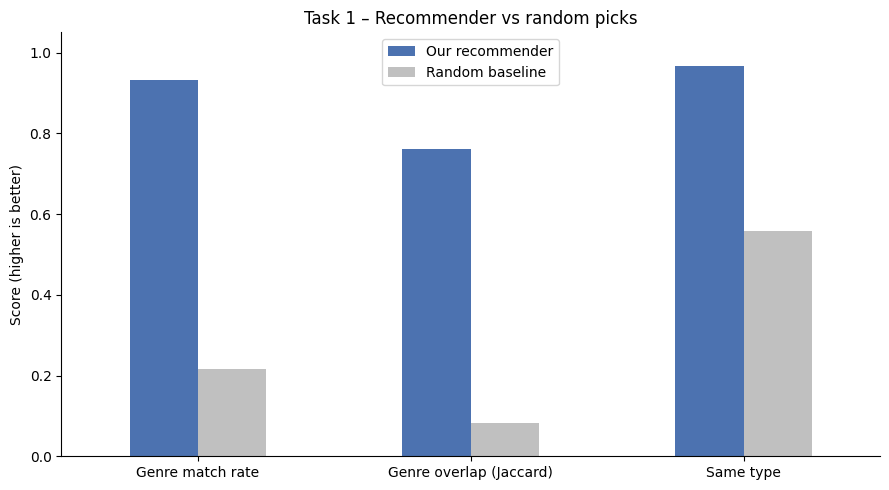

In [ ]:
rng = np.random.RandomState(RANDOM_STATE)
sample = rng.choice(len(df), size=500, replace=False)

def evaluate(pick_function):
    genre_hit, jaccard, same_type = [], [], []
    for idx in sample:
        recs = pick_function(idx)
        q_genres = set(split_items(df.loc[idx, "listed_in"]))
        for j in recs:
            r_genres = set(split_items(df.loc[j, "listed_in"]))
            overlap = len(q_genres & r_genres)
            genre_hit.append(overlap > 0)
            jaccard.append(overlap / len(q_genres | r_genres))
            same_type.append(df.loc[j, "type"] == df.loc[idx, "type"])
    return {"Genre match rate": np.mean(genre_hit),
            "Genre overlap (Jaccard)": np.mean(jaccard),
            "Same type": np.mean(same_type)}

def model_picks(idx):
    scores = linear_kernel(tfidf_matrix[idx], tfidf_matrix).ravel()
    return [i for i in scores.argsort()[::-1] if i != idx][:5]

def random_picks(idx):
    others = [i for i in rng.choice(len(df), size=10, replace=False) if i != idx]
    return others[:5]

results = pd.DataFrame({"Our recommender": evaluate(model_picks),
                        "Random baseline": evaluate(random_picks)}).round(3)
display(results)

results.plot(kind="bar", rot=0, color=["#4c72b0", "#c0c0c0"])
plt.title("Task 1 – Recommender vs random picks")
plt.ylabel("Score (higher is better)")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Conclusion

- The recommender returns titles that share genres, and it clearly beats random picks on every metric (see the table above).
- Franchises and same-director titles surface naturally because rare tokens like a director's name carry a lot of weight.
- **Limitations:** with no plot description or cast, two titles in the same broad genre can still feel very different. Adding descriptions, cast, or viewing-history data would be the next improvement.